# MAML-KT

**Goal:** GRU-based DKT with projected target-item embedding fused before the readout layer. 

Training for each student:
- Support: gradient descent on $\mathcal{L}^{s}_{\text{support}}$ $\rightarrow$ $\frac{\partial \mathcal{L}_{\text{support}}}{\partial \theta}$ for meta-optimization.
- Meta-loss on query: $\theta_{s} \rightarrow \mathcal{L}^{s}_{query}$ on remaining $\rightarrow$ averaged.
- Outer-update: backpropagate through the inner updates & update the shared initialization, $\theta \leftarrow \theta - \beta \nabla_{\theta}(\frac{1}{\beta} \sum_{s=1}^{\beta} \mathcal{L}^{s}_{query})$

$\theta_{T}$ is optimized along with the query loss minimization from the adapted parameters $\theta'_{T}$ from inner loop.

$$
\min\limits_{\theta} \mathbb{E}_{\mathcal{T}\sim p(\mathcal{T})} \left[\mathcal{L}^{^\text{query}}_{\mathcal{T}} (\theta'_{\mathcal{T}}) \right]
\quad
\text{s.t.}
\quad
\theta'_{\mathcal{T}} = \theta - \alpha \nabla_{\theta} \mathcal{L}^{\text{support}}_{\mathcal{T}}(\theta)
$$

**Source to audit:** [authors' `models/maml.py`](https://github.com/Indronil-Prince/MAML-KT/blob/main/models/maml.py) and [MAML-KT paper](https://arxiv.org/html/2603.00137).

**Reproduction scope.** Paper-style (not claimed to be identical to published Table 1): the paper describes `Q3–10` and `Q11–15`, five splits, and 10/20/50 held-out students. The exact published student IDs/seeds and its support indexing are not fully specified. The authors' code counts **next-step pairs**, whereas the paper describes **raw interactions**. Here `SUPPORT_INTERACTIONS=2` means two *observed responses*, one supervised support pair, and first query Q3. To inspect the code convention, later use `SUPPORT_INTERACTIONS=3` and `INNER_STEPS=2` (first query Q4; Q3–10 cannot be fully reported).

The only lightweight check is a gradient/shape check on a *real processed student*. No simulation, no ERM, and no other KT baselines. No GitHub files are modified.

## 1. Configuration

In [ ]:
import copy, json, random, sys
from collections import OrderedDict
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from torch import nn
from torch.func import functional_call

CWD = Path.cwd()
PROJECT_ROOT = Path().cwd().resolve().parent.parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
from src.ktlab.data.cli import run_pipeline

RAW_PATH = PROJECT_ROOT / 'data/raw/ASSISTment2009.csv'
PROCESSED_DIR = PROJECT_ROOT / 'data/processed/ASSISTment2009MAML'
PROCESSED_PATH = PROCESSED_DIR / 'ASSISTment2009MAML.csv'
OUTPUT_DIR = PROJECT_ROOT / 'outputs/maml/ASSISTment2009'
EDA_DIR = OUTPUT_DIR / 'eda'
PAPER_DIR = OUTPUT_DIR / 'paper'

SEED = 42
MIN_STUDENT_INTERACTIONS = 20
SUPPORT_INTERACTIONS = 2       # Two observed interactions; query predictions start at Q3
EMBEDDING_DIM, HIDDEN_DIM = 128, 256
INNER_LR, INNER_STEPS = 0.005, 1  # Paper §4.2: one update; authors' main code: two
OUTER_LR, META_BATCH_SIZE, EPOCHS = 0.001, 16, 10
COHORT_SIZES = (10,)            # Full reproduction study: (10, 20, 50)
SPLIT_COUNT = 1                 # Full reproduction study: 5

random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
torch.backends.cudnn.enabled = False
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

for folder in (PROCESSED_DIR, EDA_DIR, PAPER_DIR):
    folder.mkdir(parents=True, exist_ok=True)

print('Project root:', PROJECT_ROOT)
print('EDA figures:', EDA_DIR)
print('Paper figures:', PAPER_DIR)
print('Device:', DEVICE, '| support:', SUPPORT_INTERACTIONS,
      '| earliest query: Q'+str(SUPPORT_INTERACTIONS+1))

Project root: c:\Users\Dell ProMax Tower T2\Downloads\code\kt-state-lab
EDA figures: c:\Users\Dell ProMax Tower T2\Downloads\code\kt-state-lab\outputs\maml\ASSISTment2009\eda
Paper figures: c:\Users\Dell ProMax Tower T2\Downloads\code\kt-state-lab\outputs\maml\ASSISTment2009\paper
Device: cpu | support: 2 | earliest query: Q3


## 2. Raw data EDA (before cleaning)
The raw file may repeat a student interaction for each KC annotation. Distinguish CSV row counts from actual `(user_id, order_id)` interactions.

Source rows: 525534 | students: 4217 | questions: 26688


,order_id,assignment_id,user_id,assistment_id,problem_id,original,correct,attempt_count,ms_first_response,tutor_mode,...,hint_count,hint_total,overlap_time,template_id,answer_id,answer_text,first_action,bottom_hint,opportunity,opportunity_original
0,33022537,277618,64525,33139,51424,1,1,1,32454,tutor,...,0,3,32454,30799,NaN,26,0,NaN,1,1
1,33022709,277618,64525,33150,51435,1,1,1,4922,tutor,...,0,3,4922,30799,NaN,55,0,NaN,2,2
2,35450204,220674,70363,33159,51444,1,0,2,25390,tutor,...,0,3,42000,30799,NaN,88,0,NaN,1,1
3,35450295,220674,70363,33110,51395,1,1,1,4859,tutor,...,0,3,4859,30059,NaN,41,0,NaN,2,2
4,35450311,220674,70363,33196,51481,1,0,14,19813,tutor,...,3,4,124564,30060,NaN,65,0,0,3,3


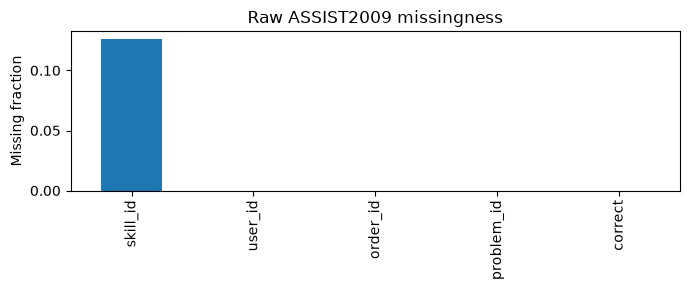

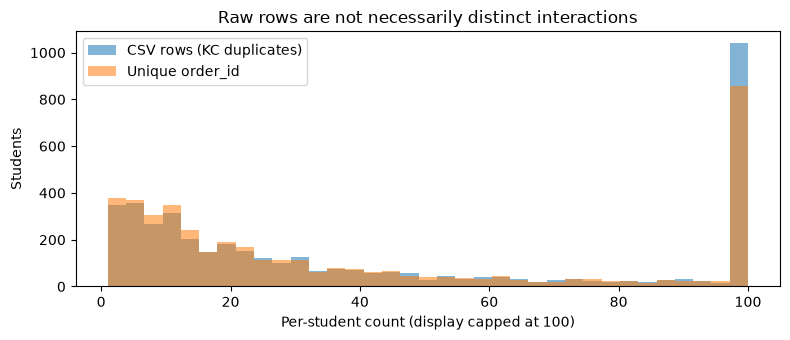

In [ ]:
raw = pd.read_csv(RAW_PATH, dtype=str, low_memory=False, encoding='cp1252')
print('Source rows:', len(raw), '| students:', raw.user_id.nunique(),
      '| questions:', raw.problem_id.nunique())
display(raw.head())

fields = ['user_id', 'order_id', 'problem_id', 'skill_id', 'correct']
missing = raw[fields].isna().mean().sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(7, 3))
missing.plot.bar(ax=ax)
ax.set_ylabel('Missing fraction')
ax.set_title('Raw ASSIST2009 missingness')
fig.tight_layout()
fig.savefig(EDA_DIR/'raw_missingness.png', dpi=200, bbox_inches='tight')
plt.show()

raw_rows = raw.groupby('user_id').size()
raw_interactions = raw.groupby('user_id')['order_id'].nunique()

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.hist(raw_rows.clip(upper=100), bins=35, alpha=.55,
        label='CSV rows (KC duplicates)')
ax.hist(raw_interactions.clip(upper=100), bins=35, alpha=.55,
        label='Unique order_id')
ax.set(xlabel='Per-student count (display capped at 100)', ylabel='Students',
       title='Raw rows are not necessarily distinct interactions')
ax.legend()
fig.tight_layout()
fig.savefig(EDA_DIR/'raw_rows_vs_interactions.png', dpi=200,
            bbox_inches='tight')
plt.show()

## 3. Preprocess ASSIST2009 using the src/ pipeline.
Combine KC annotations for the same interaction, order by `order_id`, retain students with at least 20 interactions, and let `run_pipeline` validate the resulting dataset. All processed artifacts stay in `data/processed/ASSISTment2009MAML/`. The missing-KC filter is kept from the previous notebook and must be documented when comparing to the authors’ data.

In [3]:
clean = raw.dropna(subset=['user_id', 'order_id', 'problem_id', 'skill_id', 'correct']).copy()
clean['correct'] = pd.to_numeric(clean['correct'], errors='coerce')
clean['order_number'] = pd.to_numeric(clean['order_id'], errors='coerce')
clean = clean[clean.correct.isin([0, 1]) & clean.order_number.notna()].copy()
clean = clean.sort_values(['user_id', 'order_number'], kind='stable')

conflict_counts = clean.groupby(['user_id', 'order_id'])[['problem_id', 'correct']].nunique()
conflicts = int(conflict_counts.gt(1).any(axis=1).sum())
print('Conflicting question/answer groups:', conflicts)
if conflicts:
    raise ValueError('Conflicting interaction labels; inspect raw rows before aggregating')

processed = clean.groupby(['user_id', 'order_id'], sort=False, as_index=False).agg(
    question_id=('problem_id', 'first'), correct=('correct', 'first'),
    order_number=('order_number', 'first'),
    kc_ids=('skill_id', lambda values: ';'.join(dict.fromkeys(
        kc for value in values for kc in value.split('_') if kc
    )))
)
processed = processed.rename(columns={'user_id':'student_id', 'order_id':'interaction_id'})
processed = processed.sort_values(['student_id', 'order_number'], kind='stable')
lengths = processed.groupby('student_id')['student_id'].transform('size')
processed = processed[lengths >= MIN_STUDENT_INTERACTIONS].copy()
processed['step'] = processed.groupby('student_id').cumcount() + 1
processed['timestamp'] = ''; processed['question_text'] = ''
processed = processed[['student_id', 'interaction_id', 'step', 'question_id',
                       'kc_ids', 'correct', 'timestamp', 'question_text']]
processed.to_csv(PROCESSED_PATH, index=False)

conversion = pd.DataFrame([{
    'raw_csv_rows': len(raw), 'rows_after_missing_and_label_filter': len(clean),
    'unique_interactions_before_length_filter': len(conflict_counts),
    'processed_interactions': len(processed),
    'processed_students': processed.student_id.nunique(),
    'merged_extra_kc_annotation_rows': len(clean) - len(conflict_counts),
    'conflicting_groups': conflicts
}])
conversion.to_csv(PROCESSED_DIR/'conversion_summary.csv', index=False)
display(conversion)

manifest = run_pipeline(PROCESSED_PATH, PROCESSED_DIR, seed=SEED,
                        support_sizes=(SUPPORT_INTERACTIONS,))
print('Student splits:', manifest['counts']['students'])

Conflicting question/answer groups: 0


,raw_csv_rows,rows_after_missing_and_label_filter,unique_interactions_before_length_filter,processed_interactions,processed_students,merged_extra_kc_annotation_rows,conflicting_groups
0,525534,459208,283105,265502,2131,176103,0


Student splits: {'train': 1705, 'val': 213, 'test': 213}


## 4. EDA after preprocessing
The team’s standard 80/10/10 split is used only for preprocessing diagnostics.
Paper-style cohort experiments are created separately below.

Every EDA table/figure in this section is saved to:

`outputs/maml/ASSISTment2009/eda/`

The figures are stored separately so they can be inserted directly into the presentation.


,split,students,interactions,mean_correct,eligible_for_K
0,train,1705,219017,0.658383,1705
1,val,213,22619,0.667138,213
2,test,213,23866,0.656918,213


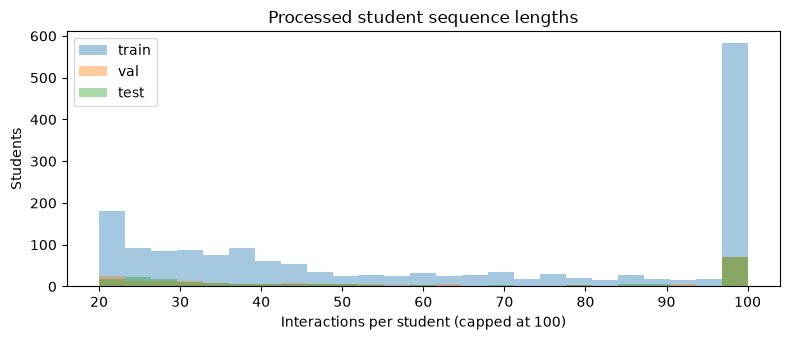

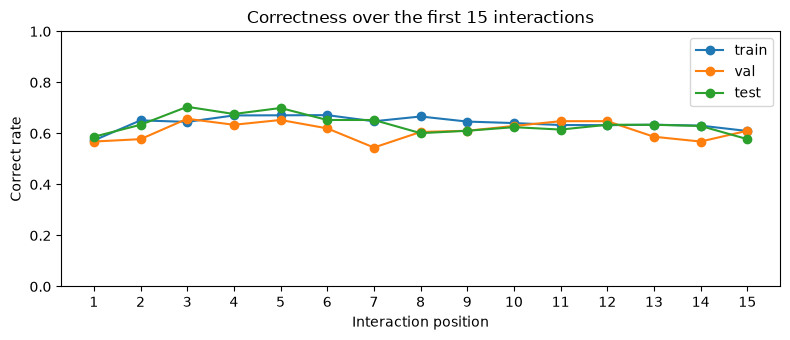

split,test,train,val
K,,,
2,213,1705,213
3,213,1705,213
5,213,1705,213
10,213,1705,213


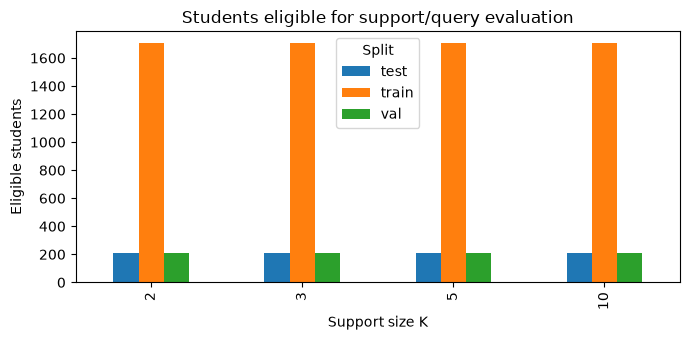

Saved EDA files:
 - outputs\maml\ASSISTment2009\eda\early_correctness_by_position.png
 - outputs\maml\ASSISTment2009\eda\processed_eda.png
 - outputs\maml\ASSISTment2009\eda\processed_sequence_lengths.png
 - outputs\maml\ASSISTment2009\eda\raw_missingness.png
 - outputs\maml\ASSISTment2009\eda\raw_rows_vs_interactions.png
 - outputs\maml\ASSISTment2009\eda\raw_sequence_lengths.png
 - outputs\maml\ASSISTment2009\eda\split_summary.csv
 - outputs\maml\ASSISTment2009\eda\support_coverage.csv
 - outputs\maml\ASSISTment2009\eda\support_coverage.png


In [4]:
SPLIT_DIR = PROCESSED_DIR / 'splits'
splits = {part: pd.read_csv(SPLIT_DIR/f'{part}.csv',
    dtype={'student_id':str, 'question_id':str, 'kc_ids':str})
    for part in ('train', 'val', 'test')}

summary = pd.DataFrame([{
    'split':part, 'students':frame.student_id.nunique(),
    'interactions':len(frame), 'mean_correct':frame.correct.mean(),
    'eligible_for_K':int((frame.groupby('student_id').size() >
                          SUPPORT_INTERACTIONS).sum())
} for part,frame in splits.items()])
display(summary)
summary.to_csv(EDA_DIR/'split_summary.csv', index=False)

fig, ax = plt.subplots(figsize=(8, 3.5))
for part, frame in splits.items():
    length = frame.groupby('student_id').size()
    ax.hist(length.clip(upper=100), bins=25, alpha=.4, label=part)
ax.set(xlabel='Interactions per student (capped at 100)', ylabel='Students',
       title='Processed student sequence lengths')
ax.legend()
fig.tight_layout()
fig.savefig(EDA_DIR/'processed_sequence_lengths.png', dpi=200,
            bbox_inches='tight')
plt.show()

fig, ax = plt.subplots(figsize=(8, 3.5))
for part, frame in splits.items():
    early = frame[frame.step.between(1, 15)].groupby('step').correct.mean()
    ax.plot(early.index, early.values, marker='o', label=part)
ax.set(xlabel='Interaction position', ylabel='Correct rate',
       title='Correctness over the first 15 interactions', ylim=(0, 1))
ax.set_xticks(range(1, 16))
ax.legend()
fig.tight_layout()
fig.savefig(EDA_DIR/'early_correctness_by_position.png', dpi=200,
            bbox_inches='tight')
plt.show()

coverage = pd.DataFrame([{
    'split':part, 'K':k,
    'eligible_students':int((frame.groupby('student_id').size() > k).sum())
} for part,frame in splits.items() for k in (2, 3, 5, 10)])
coverage_table = coverage.pivot(index='K', columns='split',
                                values='eligible_students')
display(coverage_table)
coverage.to_csv(EDA_DIR/'support_coverage.csv', index=False)

fig, ax = plt.subplots(figsize=(7, 3.5))
coverage_table.plot.bar(ax=ax)
ax.set(xlabel='Support size K', ylabel='Eligible students',
       title='Students eligible for support/query evaluation')
ax.legend(title='Split')
fig.tight_layout()
fig.savefig(EDA_DIR/'support_coverage.png', dpi=200,
            bbox_inches='tight')
plt.show()

print('Saved EDA files:')
for file in sorted(EDA_DIR.glob('*')):
    print(' -', file.relative_to(PROJECT_ROOT))


## 5. Causal next-step tasks and GRU model
From $(q_t,y_t)$ predict $y_{t+1}$ given $q_{t+1}$. A support prefix of `K` observed raw interactions yields `K-1` supervised support pairs. Query predictions begin at raw interaction `K+1`. This intentionally resets the GRU hidden state for the query suffix, like the authors’ released MAML implementation.

In [5]:
class DKTGRU(nn.Module):
    def __init__(self, num_questions, embedding_dim, hidden_dim):
        super().__init__()
        self.interaction_embedding = nn.Embedding(2*num_questions, embedding_dim, padding_idx=0)
        self.question_embedding = nn.Embedding(num_questions, embedding_dim, padding_idx=0)
        self.gru = nn.GRU(embedding_dim, hidden_dim, batch_first=True)
        self.target_projection = nn.Linear(embedding_dim, hidden_dim)
        self.head = nn.Linear(hidden_dim, 1)

    def forward(self, interactions, target_questions):
        hidden, _ = self.gru(self.interaction_embedding(interactions))
        target = self.target_projection(self.question_embedding(target_questions))
        return self.head(hidden + target).squeeze(-1)


def make_tasks(frame, vocabulary, token_count):
    tasks = []
    for student, history in frame.groupby('student_id', sort=False):
        history = history.sort_values('step')
        if len(history) <= SUPPORT_INTERACTIONS:
            continue
        questions = np.array([vocabulary.get(str(q),1) for q in history.question_id], dtype=np.int64)
        labels = history.correct.to_numpy(dtype=np.int64)
        x = torch.tensor(questions[:-1] + token_count * labels[:-1], device=DEVICE)
        q_next = torch.tensor(questions[1:], device=DEVICE)
        y_next = torch.tensor(labels[1:], dtype=torch.float32, device=DEVICE)
        boundary = SUPPORT_INTERACTIONS - 1
        kc_list = [set(str(k).split(';')) for k in history.kc_ids]
        known = set()
        newly_seen = []
        for kcs in kc_list:
            newly_seen.append(bool(kcs - known))
            known.update(kcs)
        tasks.append({
            'student_id':student,
            'support':(x[:boundary], q_next[:boundary], y_next[:boundary]),
            'query':(x[boundary:], q_next[boundary:], y_next[boundary:]),
            'positions':list(range(SUPPORT_INTERACTIONS+1, len(history)+1)),
            'new_student_kc':newly_seen[SUPPORT_INTERACTIONS:]
        })
    return tasks

## 6. Second-order MAML: task adaptation, meta-optimization, and evaluation
All inner updates are **support-only**. Query labels update the shared initialization during meta-training but never enter test-time adaptation. For evaluation, `create_graph=False` avoids unnecessary higher-order graphs. cuDNN is disabled for GRU higher-order derivatives.

In [6]:
def loss_for(model, params, pairs):
    interactions, questions, labels = pairs
    logits = functional_call(model, params, (interactions[None,:], questions[None,:]))[0]
    return nn.functional.binary_cross_entropy_with_logits(logits, labels)


def adapt(model, support, second_order):
    fast = OrderedDict(model.named_parameters())
    for _ in range(INNER_STEPS):
        support_loss = loss_for(model, fast, support)
        gradients = torch.autograd.grad(support_loss, tuple(fast.values()),
                                        create_graph=second_order)
        fast = OrderedDict((name, value-INNER_LR*grad)
                           for (name,value),grad in zip(fast.items(), gradients))
    return fast


def train_epoch(model, optimizer, tasks, epoch, seed):
    model.train()
    order = list(range(len(tasks)))
    random.Random(seed+epoch).shuffle(order)
    losses = []
    for start in range(0, len(order), META_BATCH_SIZE):
        batch = [tasks[i] for i in order[start:start+META_BATCH_SIZE]]
        optimizer.zero_grad()
        query_losses = [loss_for(model, adapt(model, task['support'], True), task['query'])
                        for task in batch]
        torch.stack(query_losses).mean().backward()
        optimizer.step()
        losses.extend(loss.detach().item() for loss in query_losses)
    return float(np.mean(losses))


def predict(model, tasks):
    model.eval()
    rows = []
    for task in tasks:
        with torch.enable_grad():
            adapted = adapt(model, task['support'], False)
        initial = OrderedDict(model.named_parameters())
        query = task['query']
        inputs = (query[0][None,:], query[1][None,:])
        with torch.no_grad():
            p_before = functional_call(model, initial, inputs).sigmoid()[0].cpu().numpy()
            p_after = functional_call(model, adapted, inputs).sigmoid()[0].cpu().numpy()
        for pos, label, p0, p1, new_kc in zip(
            task['positions'], query[2].cpu().numpy(), p_before, p_after, task['new_student_kc']):
            rows.append({'student_id':task['student_id'], 'position':pos,
                'correct':int(label), 'p_before':float(p0), 'p_after':float(p1),
                'new_student_kc':bool(new_kc)})
    return pd.DataFrame(rows)


def scores(pred, column):
    p = pred[column].clip(1e-7,1-1e-7)
    y = pred.correct
    return {'accuracy':float(((p>=0.5)==y).mean()),
        'bce':float(-(y*np.log(p)+(1-y)*np.log(1-p)).mean()),
        'brier':float(((p-y)**2).mean())}


def window_scores(pred, column, lo, hi):
    selected = pred[pred.position.between(lo,hi)].copy()
    selected['hit'] = (selected[column]>=0.5)==selected.correct
    per_position = selected.groupby('position').hit.mean()
    result = scores(selected,column)
    result.update({'position_avg_accuracy':float(per_position.mean()),
        'positions':len(per_position), 'predictions':len(selected)})
    return result

## 7. Short real-student gradient check
This is a tiny correctness check, **not a synthetic training run**. Use one processed student and verify the outer gradient reaches the shared initialization.

In [7]:
student_ids = np.array(sorted(processed.student_id.astype(str).unique()))
example_student = processed[processed.student_id == student_ids[0]]
example_vocab = {str(q):i+2 for i,q in enumerate(sorted(example_student.question_id.unique()))}
example_task = make_tasks(example_student, example_vocab, len(example_vocab)+2)[0]
check_model = DKTGRU(len(example_vocab)+2, 8, 16).to(DEVICE)
query_loss = loss_for(check_model, adapt(check_model, example_task['support'], True),
                      example_task['query'])
gradients = torch.autograd.grad(query_loss, tuple(check_model.parameters()))
print('Support pairs:',example_task['support'][2].numel(),
      '| earliest query Q'+str(example_task['positions'][0]),
      '| gradient norm:',round(float(torch.linalg.vector_norm(
          torch.stack([g.norm() for g in gradients]))),6))

Support pairs: 1 | earliest query Q3 | gradient norm: 0.332419


## 8. Held-out student cohorts — **MAML only**
Each `cohort_size × split` has a fresh student-disjoint train/validation/test assignment. Each split gets a **new model**, its own train-only question vocabulary, and a validation-selected checkpoint. The authors' repository includes some processed cohorts, but the exact paper split identities and raw preprocessing remain unverified; these are reproducible **paper-style random cohorts**, not the authors' exact splits.

The initial run uses `(10,) × 1` at the **full model dimensions and 10 epochs**. Once inspected, set `COHORT_SIZES=(10,20,50)` and `SPLIT_COUNT=5` in Section 1 to run all 15 splits.

In [8]:
(PROCESSED_DIR / 'paper_splits').mkdir(parents=True, exist_ok=True)


def prepare_split(cohort_size, split_number):
    seed = SEED + 1000*cohort_size + split_number
    student_ids = np.array(sorted(processed.student_id.astype(str).unique()))
    shuffled = np.random.default_rng(seed).permutation(student_ids)
    test_ids = set(shuffled[:cohort_size])
    val_count = max(1, round(.1*(len(shuffled)-cohort_size)))
    val_ids = set(shuffled[cohort_size:cohort_size+val_count])
    roles = pd.DataFrame({'student_id':student_ids})
    roles['split'] = roles.student_id.map(
        lambda sid:'test' if sid in test_ids else ('val' if sid in val_ids else 'train'))
    roles.to_csv(PROCESSED_DIR/'paper_splits'/f'cohort_{cohort_size}_split_{split_number}.csv',index=False)
    parts = {name:processed[processed.student_id.isin(
        roles.loc[roles.split.eq(name),'student_id'])].copy()
        for name in ('train','val','test')}
    vocabulary = {str(q):i+2 for i,q in enumerate(sorted(parts['train'].question_id.unique()))}
    token_count = len(vocabulary)+2
    tasks = {name:make_tasks(frame,vocabulary,token_count) for name,frame in parts.items()}
    return seed, tasks, token_count


## 9. Train, validate, and save split-level MAML predictions
Checkpoint selection uses **validation position-averaged accuracy** over the available critical window. Test predictions are computed only after checkpoint selection. Both pre-adaptation (`p_before`) and adapted (`p_after`) probabilities are exported.

In [9]:
split_rows, position_rows, histories, all_predictions = [], [], [], []
critical_start = max(3, SUPPORT_INTERACTIONS+1)
critical_name = 'critical_3_10' if critical_start==3 else f'partial_{critical_start}_10'

for cohort_size in COHORT_SIZES:
    for split_number in range(1, SPLIT_COUNT+1):
        seed, tasks, num_questions = prepare_split(cohort_size, split_number)
        folder = PAPER_DIR/f'cohort_{cohort_size}'/f'split_{split_number}'
        folder.mkdir(parents=True,exist_ok=True)
        torch.manual_seed(seed)
        model = DKTGRU(num_questions, EMBEDDING_DIM, HIDDEN_DIM).to(DEVICE)
        optimizer = torch.optim.Adam(model.parameters(),lr=OUTER_LR,weight_decay=1e-4)
        best_score, best_state, best_epoch = -1., None, 0
        print(f'\nCohort {cohort_size}, split {split_number} | students:',
              {k:len(v) for k,v in tasks.items()})

        for epoch in range(1,EPOCHS+1):
            train_loss = train_epoch(model,optimizer,tasks['train'],epoch,seed)
            val_pred = predict(model,tasks['val'])
            val_score = window_scores(val_pred,'p_after',critical_start,10)
            val_bce = scores(val_pred,'p_after')['bce']
            histories.append({'cohort_size':cohort_size,'split':split_number,'epoch':epoch,
                'train_query_bce':train_loss,'val_query_bce':val_bce,
                'val_critical_accuracy':val_score['position_avg_accuracy']})
            if val_score['position_avg_accuracy'] > best_score:
                best_score = val_score['position_avg_accuracy']
                best_state, best_epoch = copy.deepcopy(model.state_dict()),epoch
            print(f'  Epoch {epoch}: train={train_loss:.4f}, val BCE={val_bce:.4f}, '
                  f'val {critical_name}={val_score["position_avg_accuracy"]:.3f}')

        model.load_state_dict(best_state)
        test_pred = predict(model,tasks['test'])
        test_pred.to_csv(folder/'test_predictions.csv',index=False)
        torch.save(best_state,folder/'maml_model.pt')
        with (folder/'config.json').open('w') as file:
            json.dump({'cohort_size':cohort_size,'split':split_number,'seed':seed,
                'support_interactions':SUPPORT_INTERACTIONS,'inner_steps':INNER_STEPS,
                'inner_lr':INNER_LR,'outer_lr':OUTER_LR,'epochs':EPOCHS,
                'embedding_dim':EMBEDDING_DIM,'hidden_dim':HIDDEN_DIM,
                'best_epoch':best_epoch,'best_val_critical_acc':best_score,
                'train_students':len(tasks['train']), 'val_students':len(tasks['val']),
                'test_students':len(tasks['test'])},file,indent=2)

        for label,lo,hi in [(critical_name,critical_start,10),('moderate_11_15',11,15)]:
            for stage,col in [('before','p_before'),('after','p_after')]:
                split_rows.append({'cohort_size':cohort_size,'split':split_number,
                    'adaptation':stage,'window':label,
                    **window_scores(test_pred,col,lo,hi)})
        early = test_pred[test_pred.position.between(3,20)].copy()
        early['hit'] = (early.p_after>=.5)==early.correct
        early['brier_improvement'] = (early.p_before-early.correct)**2-(early.p_after-early.correct)**2
        for position,group in early.groupby('position'):
            position_rows.append({'cohort_size':cohort_size,'split':split_number,
                'position':position,'accuracy':group.hit.mean(),
                'brier_improvement':group.brier_improvement.mean(),
                'students':group.student_id.nunique()})
        all_predictions.append(test_pred.assign(cohort_size=cohort_size,split=split_number))

split_results = pd.DataFrame(split_rows)
position_results = pd.DataFrame(position_rows)
history = pd.DataFrame(histories)
predictions = pd.concat(all_predictions,ignore_index=True)
split_results.to_csv(PAPER_DIR/'split_results.csv',index=False)
position_results.to_csv(PAPER_DIR/'position_results.csv',index=False)
history.to_csv(PAPER_DIR/'history.csv',index=False)
display(split_results[['cohort_size','split','adaptation','window','position_avg_accuracy','bce','brier']].round(4))


Cohort 10, split 1 | students: {'train': 1909, 'val': 212, 'test': 10}
  Epoch 1: train=0.6701, val BCE=0.6454, val critical_3_10=0.644
  Epoch 2: train=0.6593, val BCE=0.6342, val critical_3_10=0.643
  Epoch 3: train=0.6536, val BCE=0.6308, val critical_3_10=0.657
  Epoch 4: train=0.6430, val BCE=0.6369, val critical_3_10=0.656
  Epoch 5: train=0.6342, val BCE=0.6259, val critical_3_10=0.652
  Epoch 6: train=0.6218, val BCE=0.6264, val critical_3_10=0.669
  Epoch 7: train=0.6109, val BCE=0.6281, val critical_3_10=0.658
  Epoch 8: train=0.5999, val BCE=0.6222, val critical_3_10=0.658
  Epoch 9: train=0.5900, val BCE=0.6453, val critical_3_10=0.656
  Epoch 10: train=0.5808, val BCE=0.6238, val critical_3_10=0.654


,cohort_size,split,adaptation,window,position_avg_accuracy,bce,brier
0,10,1,before,critical_3_10,0.7625,0.5899,0.1998
1,10,1,after,critical_3_10,0.7625,0.5892,0.1994
2,10,1,before,moderate_11_15,0.7800,0.5637,0.1884
3,10,1,after,moderate_11_15,0.7800,0.5639,0.1885


## 10. Paper-window summaries and diagnostic figures
All plots are recreated from saved `history.csv`, `position_results.csv`, and split prediction CSVs. A positive Brier improvement means adaptation reduces squared prediction error. The number of students contributing to each late position decreases, so early-window plots include **sample counts**.

The paper values shown in the last plot are **reference numbers**, not results from matched student splits.

,cohort_size,adaptation,window,accuracy,std,bce,brier,splits
0,10,after,critical_3_10,0.7625,NaN,0.5892,0.1994,1
1,10,after,moderate_11_15,0.7800,NaN,0.5639,0.1885,1
2,10,before,critical_3_10,0.7625,NaN,0.5899,0.1998,1
3,10,before,moderate_11_15,0.7800,NaN,0.5637,0.1884,1


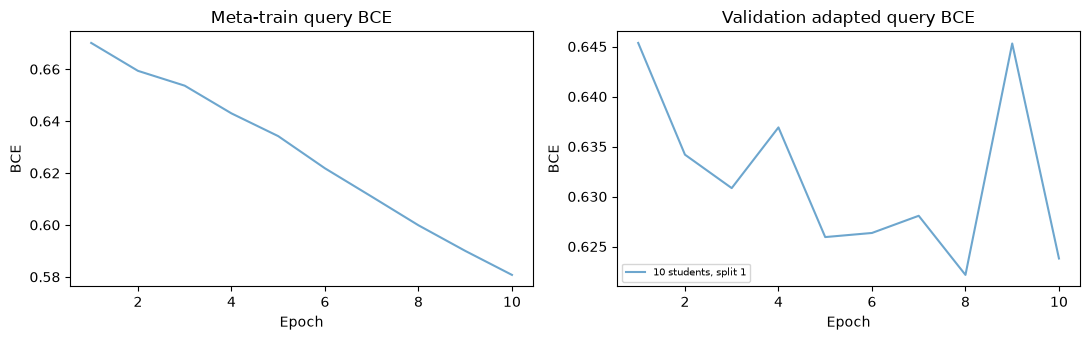

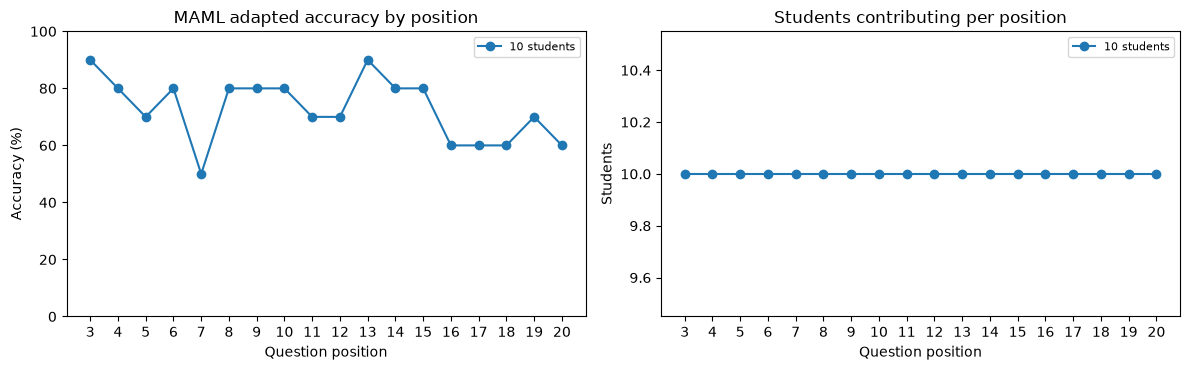

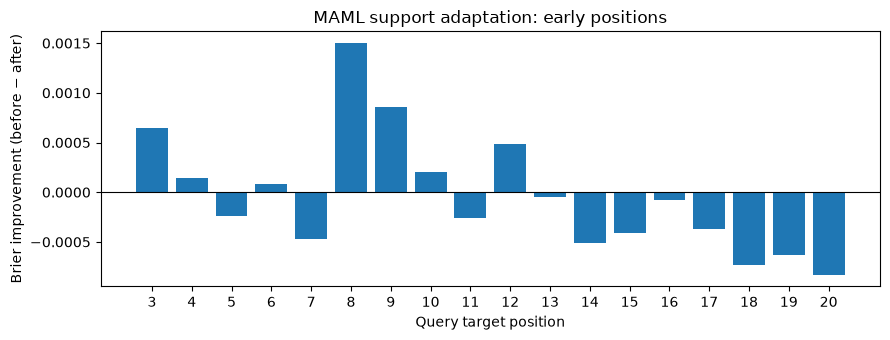

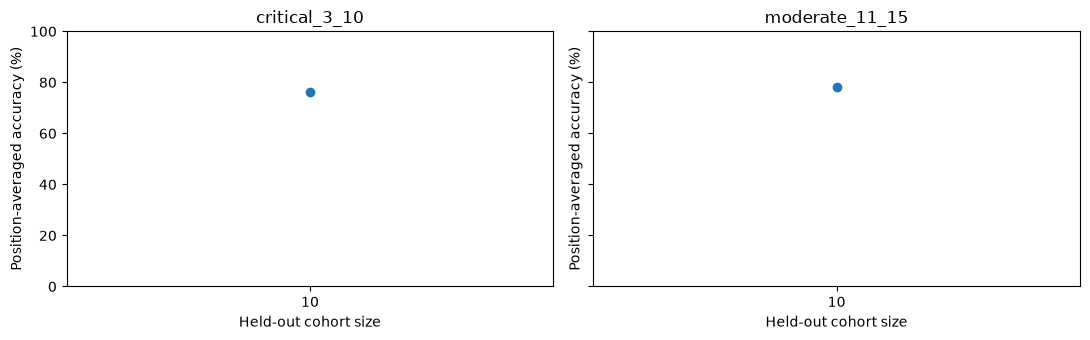

In [10]:
paper_summary = split_results.groupby(['cohort_size','adaptation','window']).agg(
    accuracy=('position_avg_accuracy','mean'),
    std=('position_avg_accuracy','std'),
    bce=('bce','mean'),brier=('brier','mean'),
    splits=('split','nunique')).reset_index()
paper_summary.to_csv(PAPER_DIR/'summary.csv',index=False)
display(paper_summary.round(4))

fig,axs = plt.subplots(1,2,figsize=(11,3.5))
for (cohort,split), group in history.groupby(['cohort_size','split']):
    label=f'{cohort} students, split {split}'
    axs[0].plot(group.epoch,group.train_query_bce,alpha=.65,label=label)
    axs[1].plot(group.epoch,group.val_query_bce,alpha=.65,label=label)
axs[0].set(title='Meta-train query BCE',xlabel='Epoch',ylabel='BCE')
axs[1].set(title='Validation adapted query BCE',xlabel='Epoch',ylabel='BCE')
axs[1].legend(fontsize=7)
plt.tight_layout();plt.savefig(PAPER_DIR/'training_validation_curves.png',dpi=160);plt.show()

fig,axs=plt.subplots(1,2,figsize=(12,3.8))
for cohort,group in position_results.groupby('cohort_size'):
    p=group.groupby('position').agg(accuracy=('accuracy','mean'),students=('students','mean'))
    axs[0].plot(p.index,100*p.accuracy,marker='o',label=f'{cohort} students')
    axs[1].plot(p.index,p.students,marker='o',label=f'{cohort} students')
axs[0].set(title='MAML adapted accuracy by position',xlabel='Question position',ylabel='Accuracy (%)',ylim=(0,100))
axs[1].set(title='Students contributing per position',xlabel='Question position',ylabel='Students')
for ax in axs: ax.set_xticks(range(3,21));ax.legend(fontsize=8)
plt.tight_layout();plt.savefig(PAPER_DIR/'early_position_accuracy_and_counts.png',dpi=160);plt.show()

improve = position_results.groupby('position').brier_improvement.mean()
plt.figure(figsize=(9,3.5));plt.bar(improve.index,improve.values)
plt.axhline(0,color='black',linewidth=.8)
plt.xticks(improve.index);plt.xlabel('Query target position')
plt.ylabel('Brier improvement (before − after)')
plt.title('MAML support adaptation: early positions')
plt.tight_layout();plt.savefig(PAPER_DIR/'early_brier_improvement.png',dpi=160);plt.show()

adapted = paper_summary[paper_summary.adaptation.eq('after')]
fig,axs=plt.subplots(1,2,figsize=(11,3.5),sharey=True)
for ax,window in zip(axs,[critical_name,'moderate_11_15']):
    d=adapted[adapted.window.eq(window)].sort_values('cohort_size')
    ax.errorbar(d.cohort_size,100*d.accuracy,yerr=100*d['std'].fillna(0),
                marker='o',capsize=3)
    ax.set(title=window,xlabel='Held-out cohort size',ylabel='Position-averaged accuracy (%)')
    ax.set_xticks(COHORT_SIZES);ax.set_ylim(0,100)
plt.tight_layout();plt.savefig(PAPER_DIR/'window_accuracy_by_cohort.png',dpi=160);plt.show()

## 11. Student-specific and KC-introduction diagnostics
A KC can be new **to this student** without being globally unseen in the training data. These diagnostics examine associations, not proof of why MAML predictions change.

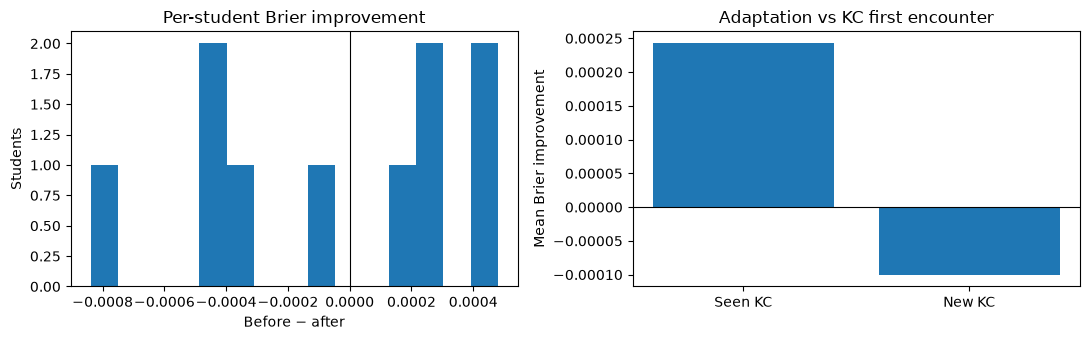

,new_student_kc,brier_improvement,responses
0,False,0.000243,96
1,True,-0.000100,34


Students with positive mean Brier improvement: 5 / 10


In [11]:
predictions['brier_change'] = (predictions.p_before-predictions.correct)**2 - (predictions.p_after-predictions.correct)**2
per_student = predictions.groupby(['cohort_size','split','student_id']).agg(
    brier_improvement=('brier_change','mean'),queries=('correct','size')).reset_index()
per_student.to_csv(PAPER_DIR/'student_adaptation.csv',index=False)

fig,axs=plt.subplots(1,2,figsize=(11,3.5))
axs[0].hist(per_student.brier_improvement,bins=15)
axs[0].axvline(0,color='black',linewidth=.8)
axs[0].set(title='Per-student Brier improvement',xlabel='Before − after',ylabel='Students')
early = predictions[predictions.position.between(SUPPORT_INTERACTIONS+1,15)].copy()
new_kc = early.groupby('new_student_kc').agg(
    brier_improvement=('brier_change','mean'),responses=('correct','size')).reset_index()
axs[1].bar(new_kc.new_student_kc.map({False:'Seen KC',True:'New KC'}),new_kc.brier_improvement)
axs[1].axhline(0,color='black',linewidth=.8)
axs[1].set(title='Adaptation vs KC first encounter',ylabel='Mean Brier improvement')
plt.tight_layout();plt.savefig(PAPER_DIR/'student_and_kc_diagnostics.png',dpi=160);plt.show()
display(new_kc)
print('Students with positive mean Brier improvement:',int((per_student.brier_improvement>0).sum()),
      '/',len(per_student))

## 12. Paper-reference comparison and one-student sequence
These two figures are **descriptive diagnostics**. Published MAML numbers are not paired to our newly sampled student cohorts. The per-student plot shows predicted correctness, observed correctness, and first-encounter KCs, but does not reveal an identifiable latent mastery state.

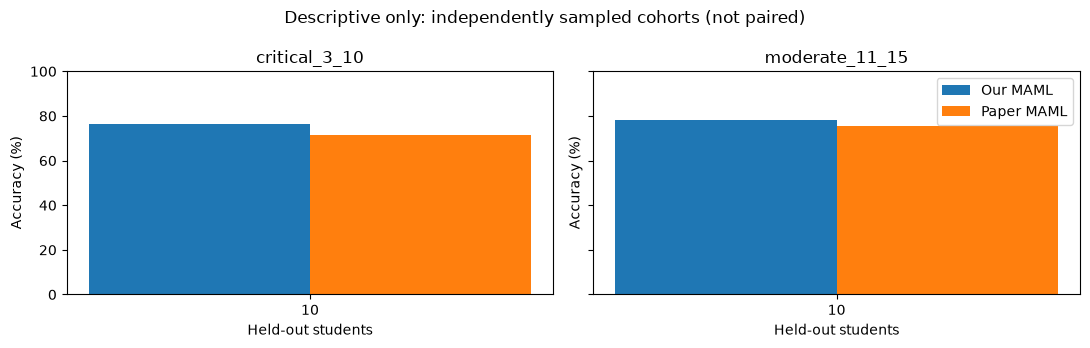

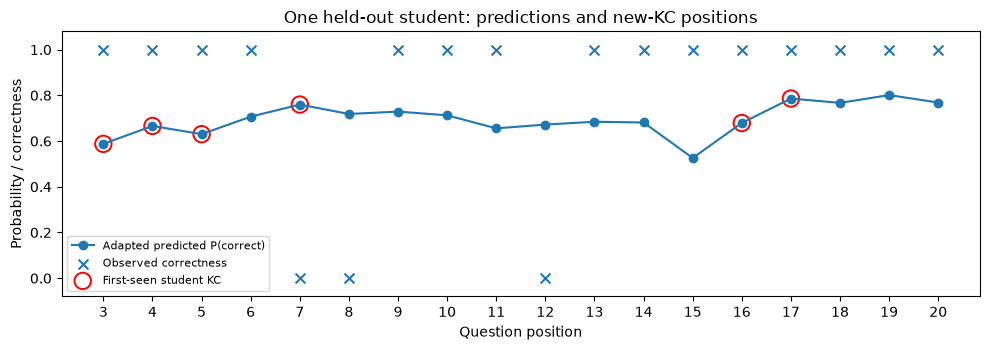

In [12]:
# Published ASSIST2009 MAML values from Table 1 (percent, 5 sets per cohort)
published = {
    (10,'critical_3_10'):[75.3,75.9,72.3,67.2,66.8],
    (20,'critical_3_10'):[81.1,76.8,81.0,75.5,81.9],
    (50,'critical_3_10'):[80.1,77.8,74.4,77.1,77.5],
    (10,'moderate_11_15'):[79.4,78.1,76.6,71.9,70.5],
    (20,'moderate_11_15'):[82.6,80.9,82.7,82.0,84.6],
    (50,'moderate_11_15'):[85.0,78.4,72.0,79.6,77.2],
}
reference = pd.DataFrame([{'cohort_size':n,'window':window,
    'published_mean_accuracy':np.mean(vals)/100}
    for (n,window),vals in published.items()])
current = paper_summary[paper_summary.adaptation.eq('after')][
    ['cohort_size','window','accuracy']]
reference = current.merge(reference,on=['cohort_size','window'],how='left')
reference.to_csv(PAPER_DIR/'published_reference_comparison.csv',index=False)
fig,axs = plt.subplots(1,2,figsize=(11,3.5),sharey=True)
for ax,window in zip(axs,[critical_name,'moderate_11_15']):
    d=reference[reference.window.eq(window)].sort_values('cohort_size')
    x=np.arange(len(d))
    ax.bar(x-.18,100*d.accuracy,width=.36,label='Our MAML')
    ax.bar(x+.18,100*d.published_mean_accuracy,width=.36,label='Paper MAML')
    ax.set_xticks(x,[str(c) for c in d.cohort_size])
    ax.set(title=window,xlabel='Held-out students',ylabel='Accuracy (%)',ylim=(0,100))
axs[1].legend()
fig.suptitle('Descriptive only: independently sampled cohorts (not paired)')
plt.tight_layout();plt.savefig(PAPER_DIR/'published_maml_reference.png',dpi=160);plt.show()

first_cohort, first_split = COHORT_SIZES[0], 1
panel = predictions[(predictions.cohort_size==first_cohort) &
                    (predictions.split==first_split)]
selected_student = panel.student_id.iloc[0]
trace = panel[(panel.student_id==selected_student) &
              panel.position.between(SUPPORT_INTERACTIONS+1,20)].copy()
plt.figure(figsize=(10,3.6))
plt.plot(trace.position,trace.p_after,'o-',label='Adapted predicted P(correct)')
plt.scatter(trace.position,trace.correct,marker='x',s=50,label='Observed correctness')
novel = trace[trace.new_student_kc]
plt.scatter(novel.position,novel.p_after,facecolors='none',edgecolors='red',
            s=140,linewidths=1.4,label='First-seen student KC')
plt.xticks(trace.position);plt.ylim(-.08,1.08)
plt.xlabel('Question position');plt.ylabel('Probability / correctness')
plt.title('One held-out student: predictions and new-KC positions')
plt.legend(fontsize=8);plt.tight_layout()
plt.savefig(PAPER_DIR/'single_student_trace.png',dpi=160);plt.show()

## 13. Interpreting reproduction status (MAML only)

**Run settings for all paper-style cohorts:** change `COHORT_SIZES=(10,20,50)`, `SPLIT_COUNT=5` in Section 1. The default already uses 10 epochs, 128-dimensional embeddings, 256-dimensional hidden states, batch 16, and one inner gradient step. Each split retrains MAML and exports one validation-selected checkpoint.

**What matches the paper:** student-task MAML, second-order gradients, GRU with target-item projection, ≥20 interactions, new-student-disjoint cohorts, 10/20/50 × five splits (when enabled), positional accuracy and Q3–10/Q11–15 windows, observed response history only.

**Still not proven exact:** cohort identities/seeds, data preprocessing (including missing KC exclusions), authors' precise hyperparameter selection, exact definition of support size, and whether the paper's published table came from its current released script. The released `maml.py` runs two support **prediction pairs** and two gradient steps, which first evaluates Q4 rather than Q3. Do not label that version `Q3–10`.

**Paper reference, ASSIST2009 MAML accuracy (%)**, in set order 1–5: critical Q3–10: 10 students `75.3,75.9,72.3,67.2,66.8`; 20 students `81.1,76.8,81.0,75.5,81.9`; 50 students `80.1,77.8,74.4,77.1,77.5`. Moderate Q11–15: 10 students `79.4,78.1,76.6,71.9,70.5`; 20 students `82.6,80.9,82.7,82.0,84.6`; 50 students `85.0,78.4,72.0,79.6,77.2`. Because our cohorts are independently sampled, **differences from these published numbers are descriptive, not exact paired reproduction errors**.

Useful outputs: `paper/summary.csv`, `paper/split_results.csv`, `paper/position_results.csv`, `paper/history.csv`, `paper/*/*.csv`, and the saved figures. **No old experiment logs are required to run this notebook.**